# Python · Kriging with `method="vecchia"` / `"nystrom"` — large n

**Idea.** Vecchia and Nyström approximations make Kriging affordable for large n;
how much accuracy do they cost, and do they converge to the exact model as their
size parameter grows?

**Reference.** The exact model at the same θ (limits m = n − 1 and k = n), and the
exact fit.

**Tags.** class: Kriging · method: exact, vecchia, nystrom · topic: large n

The exact fit costs O(n³). `Kriging` offers:

* `method="vecchia(m)"`: Vecchia likelihood with m conditioning neighbours
  (local, recommended in low dimension);
* `method="nystrom(k)"`: low-rank Nyström approximation with k landmarks
  (global);
* `Kriging.subsetOfData`: a representative subset before an exact fit.

(`NestedKriging`, the partition-based alternative, on the same problems:
`aggregations-large-n_NestedKriging_python.ipynb`.)

Problems: Hartmann 3 (3D, local structure: Vecchia's ground) and the OTL
circuit (6D, smooth: Nyström's ground), n = 1500 (exact fit still affordable,
for reference) and n = 5000 (approximations only).

Checks:
* **convergence to the exact model** at fixed θ (Hartmann 3, n = 300): the gap
  between the approximate and the exact log-likelihood and predicted mean,
  as m (Vecchia) and k (Nyström) grow, down to the limit cases m = n − 1 and
  k = n where the approximation *is* the exact model;
* **limit cases**: Vecchia with m = n − 1 neighbours *is* the exact likelihood;
* the method is explicit at prediction time: `predict(method="exact")` on a
  Nyström/Vecchia fit raises, `method=` gives finite predictions;
* accuracy of each approximation close to the exact fit (warn-level gaps,
  error-level floors) and faster than the exact fit at n = 1500 (warn-level).

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

suite = gallery.Suite("large-n_Kriging-vecchia-nystrom_python")
print("pylibkriging", compat.version())
HAS_METHOD = compat.has("method")
if not HAS_METHOD:
    suite.check_skip("method=vecchia/nystrom", "pylibkriging without the method= argument")


def pred(k, X, **kw):
    m, s, *_ = k.predict(X, return_stdev=True, **kw)
    return np.ravel(m), np.ravel(s)


def timed(f):
    t0 = time.time()
    out = f()
    return out, time.time() - t0

pylibkriging 1.2.2


## Limit case: Vecchia with all the previous points as neighbours is exact

In [3]:
if HAS_METHOD:
    tf = TESTS["branin"]
    X, y, Xt, _ = design.dataset(tf, 40, n_test=100, seed=51)
    ke = lk.Kriging(y, X, "matern5_2")
    fixed = {"theta": np.asarray(ke.theta()).reshape(1, -1), "is_theta_estim": False}
    kv = lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed, method=f"vecchia({len(y) - 1})")
    suite.check_close("vecchia(n-1) LL == exact LL (same theta)", kv.logLikelihood(method="vecchia"),
                ke.logLikelihood(), rtol=1e-6)
    suite.check_close("vecchia(n-1) predict == exact predict", pred(kv, Xt, method="vecchia")[0], pred(ke, Xt)[0],
                rtol=1e-5, atol=1e-6 * np.std(y), severity="warn")
    kn = lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed, method=f"nystrom({len(y)})")
    suite.check_close("nystrom(n) LL == exact LL (same theta)", kn.logLikelihood(method="nystrom"), ke.logLikelihood(),
                rtol=1e-3, severity="warn")
    # the method must be explicit after an approximate fit
    suite.check_raises("nystrom fit: predict(method='exact') raises", lambda: kn.predict(Xt, return_stdev=True,
                                                                                    method="exact"))
    suite.check_true("method() reports the fit method", kv.method().startswith("vecchia") and
               kn.method().startswith("nystrom"), detail=f"{kv.method()}, {kn.method()}")

[KNOWN] vecchia(n-1) LL == exact LL (same theta): value=0.00223609 expected rtol 1e-06, atol 0 With m >= n-1 neighbours the Vecchia likelihood should be the exact one; it matches for n=20 but not for n=40 (-111.349 vs -110.834)
[WARN] vecchia(n-1) predict == exact predict: value=0.016129 expected rtol 1e-05, atol 5.26901e-05 


## Convergence to the exact model, at fixed θ

Hartmann 3, n = 300, θ of the exact fit kept fixed: the reference is the exact
model with the same hyperparameters, so the gap measures the approximation
alone (no optimizer effect). Relative gap of the log-likelihood, and RMS gap
of the predicted mean on 500 test points relative to its standard deviation.

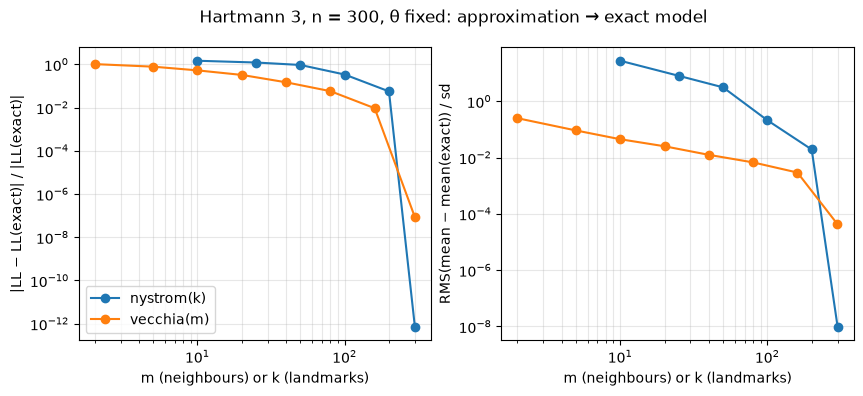

ll_gap             mean_gap          
method   nystrom   vecchia    nystrom   vecchia
size                                           
2            NaN  1.027516        NaN  0.251251
5            NaN  0.781864        NaN  0.092085
10      1.469279  0.526793  27.622761  0.044907
20           NaN  0.324638        NaN  0.025237
25      1.217603       NaN   8.042821       NaN
40           NaN  0.147929        NaN  0.012514
50      0.937844       NaN   3.133880       NaN
80           NaN  0.057523        NaN  0.006749
100     0.339028       NaN   0.211555       NaN
160          NaN  0.009344        NaN  0.002938
200     0.056189       NaN   0.019392       NaN
299          NaN  0.000000        NaN  0.000043
300     0.000000       NaN   0.000000       NaN

In [4]:
if HAS_METHOD:
    tf = TESTS["hartmann3"]
    X, y, Xt, yt = design.dataset(tf, 300, n_test=500, seed=54)
    n = len(y)
    theta = np.asarray(lk.Kriging(y, X, "matern5_2").theta()).reshape(1, -1)
    fixed = {"theta": theta, "is_theta_estim": False}
    ke = lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed)
    ll_e, m_e = ke.logLikelihood(), pred(ke, Xt)[0]
    rows = []
    for meth, sizes in [("vecchia", [2, 5, 10, 20, 40, 80, 160, n - 1]), ("nystrom", [10, 25, 50, 100, 200, n])]:
        for size in sizes:
            with suite.check_runs(f"{meth}({size}) at fixed theta: fit + predict"):
                ka = lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed, method=f"{meth}({size})")
                rows.append(dict(method=meth, size=size,
                                 ll_gap=abs(ka.logLikelihood(method=meth) - ll_e) / abs(ll_e),
                                 mean_gap=np.sqrt(np.mean((pred(ka, Xt, method=meth)[0] - m_e) ** 2)) / np.std(m_e)))
    conv = pd.DataFrame(rows)
    for meth, g in conv.groupby("method"):
        suite.metric(f"hartmann3/n={n}/fixed theta", meth, **{f"ll_gap_{s}": v for s, v in zip(g["size"], g["ll_gap"])})
        for col, lim in [("ll_gap", 1e-6), ("mean_gap", 1e-2)]:
            suite.check_less(f"{meth}: {col} at the limit size ({g['size'].iloc[-1]})", g[col].iloc[-1], lim)
            suite.check_true(f"{meth}: {col} decreases with the size", bool(np.all(np.diff(g[col].to_numpy()) < 0)),
                       detail=", ".join(f"{v:.2g}" for v in g[col]), severity="warn")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, col, label in [(axes[0], "ll_gap", "|LL − LL(exact)| / |LL(exact)|"),
                           (axes[1], "mean_gap", "RMS(mean − mean(exact)) / sd")]:
        for meth, g in conv.groupby("method"):
            ax.loglog(g["size"], g[col], "o-", label=f"{meth}(m)" if meth == "vecchia" else f"{meth}(k)")
        ax.set_xlabel("m (neighbours) or k (landmarks)"); ax.set_ylabel(label); ax.grid(True, which="both", alpha=.3)
    axes[0].legend(); fig.suptitle(f"Hartmann 3, n = {n}, θ fixed: approximation → exact model"); plt.show()
    display(conv.pivot(index="size", columns="method", values=["ll_gap", "mean_gap"]).round(6))

## Accuracy and cost

In [5]:
CASES = {"hartmann3": (1500, 5000), "otl_circuit": (1500, 5000)}
FLOORS = {"hartmann3": 0.98, "otl_circuit": 0.99}
for fname, (n_mid, n_big) in CASES.items():
    tf = TESTS[fname]
    X, y, Xt, yt = design.dataset(tf, n_big, n_test=2000, seed=52)
    Xm, ym = X[:n_mid], y[:n_mid]
    ke, t_exact = timed(lambda: lk.Kriging(ym, Xm, "matern5_2"))
    res_e = metrics.all_metrics(yt, *pred(ke, Xt))
    suite.metric(f"{fname}/n={n_mid}", "exact", fit_s=t_exact, **res_e)
    suite.check_greater(f"{fname}/n={n_mid}: Q2 exact", res_e["q2"], FLOORS[fname])
    variants = {}
    if HAS_METHOD:
        variants.update({
            "vecchia(30)": lambda Xa, ya: (lk.Kriging(ya, Xa, "matern5_2", method="vecchia(30)"), "vecchia"),
            "nystrom(100)": lambda Xa, ya: (lk.Kriging(ya, Xa, "matern5_2", method="nystrom(100)"), "nystrom"),
        })
    if compat.has("subsetOfData"):
        def sod(Xa, ya):
            idx = np.ravel(lk.Kriging.subsetOfData(Xa, n_max=500, method="kmeans", seed=1)).astype(int)
            return lk.Kriging(ya[idx], Xa[idx], "matern5_2"), None
        variants["subset of data (500)"] = sod
    for label, make in variants.items():
        for n in (n_mid, n_big):
            case = f"{fname}/n={n}"
            with suite.check_runs(f"{case}/{label}: fit + predict"):
                (k, meth), t = timed(lambda: make(X[:n], y[:n]))
                m, s = pred(k, Xt, method=meth) if meth else (
                    lambda o: (np.ravel(o[0]), np.ravel(o[1])))(k.predict(Xt, return_stdev=True))
                suite.check_finite(f"{case}/{label}: finite predictions", m)
                res = metrics.all_metrics(yt, m, s)
                suite.metric(case, label, fit_s=t, **res)
                suite.check_greater(f"{case}/{label}: Q2", res["q2"], FLOORS[fname] - 0.05)
                if n == n_mid:
                    suite.check_greater(f"{case}/{label}: Q2 - Q2(exact)", res["q2"] - res_e["q2"], -0.02,
                                  severity="warn")
                    suite.check_less(f"{case}/{label}: fit time / exact fit time", t / t_exact, 1.0, severity="warn")
suite.table().round(4)

[KNOWN] hartmann3/n=1500/nystrom(100): Q2: value=-1.39239 expected > 0.93 Nystrom predictor degrades as n grows at fixed k (theta estimates are fine: the exact predictor at the Nystrom theta has Q2 ~ 1)
[WARN] hartmann3/n=1500/nystrom(100): Q2 - Q2(exact): value=-2.39239 expected > -0.02 


[KNOWN] hartmann3/n=5000/nystrom(100): Q2: value=-102.786 expected > 0.93 Nystrom predictor degrades as n grows at fixed k (theta estimates are fine: the exact predictor at the Nystrom theta has Q2 ~ 1)


[KNOWN] otl_circuit/n=1500/nystrom(100): Q2: value=0.881068 expected > 0.94 Nystrom predictor degrades as n grows at fixed k (theta estimates are fine: the exact predictor at the Nystrom theta has Q2 ~ 1)
[WARN] otl_circuit/n=1500/nystrom(100): Q2 - Q2(exact): value=-0.118932 expected > -0.02 


[KNOWN] otl_circuit/n=5000/nystrom(100): Q2: value=0.10004 expected > 0.94 Nystrom predictor degrades as n grows at fixed k (theta estimates are fine: the exact predictor at the Nystrom theta has Q2 ~ 1)


metric                                            ll_gap_10  ll_gap_25  \
case                        package                                      
hartmann3/n=300/fixed theta nystrom                  1.4693     1.2176   
                            vecchia                  0.5268        NaN   
hartmann3/n=1500            exact                       NaN        NaN   
                            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
hartmann3/n=5000            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
otl_circuit/n=1500          exact                       NaN        NaN   
                            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
otl_circuit/n=5000          vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   

metric                                            ll_gap_50  ll_gap_100  \
case                        package                                       
hartmann3/n=300/fixed theta nystrom                  0.9378       0.339   
                            vecchia                     NaN         NaN   
hartmann3/n=1500            exact                       NaN         NaN   
                            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
hartmann3/n=5000            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
otl_circuit/n=1500          exact                       NaN         NaN   
                            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
otl_circuit/n=5000          vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   

metric                                            ll_gap_200  ll_gap_300  \
case                        package                                        
hartmann3/n=300/fixed theta nystrom                   0.0562         0.0   
                            vecchia                      NaN         NaN   
hartmann3/n=1500            exact                        NaN         NaN   
                            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
hartmann3/n=5000            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
otl_circuit/n=1500          exact                        NaN         NaN   
                            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
otl_circuit/n=5000          vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                        

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/large-n_Kriging-vecchia-nystrom_python.checks.csv` and `.metrics.csv`.

In [6]:
suite.summary()

metric                                            ll_gap_10  ll_gap_25  \
case                        package                                      
hartmann3/n=300/fixed theta nystrom                  1.4693     1.2176   
                            vecchia                  0.5268        NaN   
hartmann3/n=1500            exact                       NaN        NaN   
                            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
hartmann3/n=5000            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
otl_circuit/n=1500          exact                       NaN        NaN   
                            vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   
otl_circuit/n=5000          vecchia(30)                 NaN        NaN   
                            nystrom(100)                NaN        NaN   
                            subset of data (500)        NaN        NaN   

metric                                            ll_gap_50  ll_gap_100  \
case                        package                                       
hartmann3/n=300/fixed theta nystrom                  0.9378       0.339   
                            vecchia                     NaN         NaN   
hartmann3/n=1500            exact                       NaN         NaN   
                            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
hartmann3/n=5000            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
otl_circuit/n=1500          exact                       NaN         NaN   
                            vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   
otl_circuit/n=5000          vecchia(30)                 NaN         NaN   
                            nystrom(100)                NaN         NaN   
                            subset of data (500)        NaN         NaN   

metric                                            ll_gap_200  ll_gap_300  \
case                        package                                        
hartmann3/n=300/fixed theta nystrom                   0.0562         0.0   
                            vecchia                      NaN         NaN   
hartmann3/n=1500            exact                        NaN         NaN   
                            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
hartmann3/n=5000            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
otl_circuit/n=1500          exact                        NaN         NaN   
                            vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                            subset of data (500)         NaN         NaN   
otl_circuit/n=5000          vecchia(30)                  NaN         NaN   
                            nystrom(100)                 NaN         NaN   
                        

77 checks: PASS 69, FAIL 0, WARN 3, KNOWN 5, SKIP 0


,status,severity,check,value,expected,detail
0,KNOWN,error,vecchia(n-1) LL == exact LL (same theta),0.00223609,"rtol 1e-06, atol 0",With m >= n-1 neighbours the Vecchia likelihoo...
1,WARN,warn,vecchia(n-1) predict == exact predict,0.016129,"rtol 1e-05, atol 5.26901e-05",
2,KNOWN,error,hartmann3/n=1500/nystrom(100): Q2,-1.39239,> 0.93,Nystrom predictor degrades as n grows at fixed...
3,WARN,warn,hartmann3/n=1500/nystrom(100): Q2 - Q2(exact),-2.39239,> -0.02,
4,KNOWN,error,hartmann3/n=5000/nystrom(100): Q2,-102.786,> 0.93,Nystrom predictor degrades as n grows at fixed...
5,KNOWN,error,otl_circuit/n=1500/nystrom(100): Q2,0.881068,> 0.94,Nystrom predictor degrades as n grows at fixed...
6,WARN,warn,otl_circuit/n=1500/nystrom(100): Q2 - Q2(exact),-0.118932,> -0.02,
7,KNOWN,error,otl_circuit/n=5000/nystrom(100): Q2,0.10004,> 0.94,Nystrom predictor degrades as n grows at fixed...


In [7]:
suite.finalize()

large-n_Kriging-vecchia-nystrom_python: PASS 69, FAIL 0, WARN 3, KNOWN 5, SKIP 0


{'PASS': 69, 'FAIL': 0, 'WARN': 3, 'KNOWN': 5, 'SKIP': 0}